# El problema de inmersión: si existe un generador y cuál usar

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 02 de este tema (la matriz agrupada y el generador EM)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué plantea el problema de inmersión (¿es una matriz anual la exponencial de un generador?) y por qué importa para una PD a un horizonte distinto de un año;
- correr las verificaciones de Israel, Rosenthal y Wei sobre una matriz real y leer cada una: la convergencia de la serie del logaritmo, las tres condiciones que excluyen un generador exacto, la monotonía estocástica;
- calcular el logaritmo de matriz por su serie, encontrar sus entradas negativas fuera de la diagonal y repararlas con los ajustes diagonal, ponderado y de Jarrow-Lando-Turnbull, con cada intermedio impreso;
- comparar las reparaciones y el generador EM por la distancia L1 de la exponencial a la matriz, y por la PD que cada uno da a uno y cinco años;
- comparar el motor con las distancias que imprimen Israel et al., y decir cuál de las nueve no se reproduce y por qué.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.transitions import embedding
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos archivos versionados del caso C04:

- `data/derived/C04/sp.json`: la matriz anual agrupada de S&P del cuaderno 02 (`outputs.pooled.matrix`, retiradas removidas, siete grados e incumplimiento) y lo que el caso calculó de ella: `outputs.embedding` (los diagnósticos) y `outputs.generators` (los generadores diagonal, ponderado, JLT y EM con sus distancias L1 y sus PD a uno y cinco años). Fuente: ESMA CEREP (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/).
- `data/derived/C04/published.json`: las distancias L1 que imprimen Israel, Rosenthal y Wei para tres matrices de agencias, cada una con el valor que recalcula el motor. Las matrices del artículo no están versionadas (el artefacto guarda solo las distancias), así que esta parte del cuaderno lee la comparación y no puede repetirla.

La celda siguiente carga ambos e imprime la versión del motor que los calculó.

In [2]:
# Cargar los dos artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) y la matriz agrupada
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
published = json.loads((C04 / "published.json").read_text(encoding="utf-8"))
out = sp["outputs"]
states = out["states"]
P = np.array(out["pooled"]["matrix"], dtype=float)

for label, doc in (("sp", sp), ("published", published)):
    print(f"{label:10s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("matriz agrupada:", P.shape, "| las filas suman uno:", si_no(np.allclose(P.sum(axis=1), 1.0)))
print("diagonal de P (grados, luego incumplimiento):", np.round(np.diag(P), 4))

sp         calculado con riskvalidation 0.4.3 | instalado 0.8.1
published  calculado con riskvalidation 0.4.3 | instalado 0.8.1
matriz agrupada: (8, 8) | las filas suman uno: sí
diagonal de P (grados, luego incumplimiento): [0.8227 0.8901 0.9399 0.9294 0.8735 0.8692 0.7148 1.    ]


## Método

### Paso 1: ¿puede esta matriz tener un generador?

Una matriz de calificaciones $P$ se observa durante un año, pero un banco necesita PD a tres o cinco años, y un modelo en tiempo continuo necesita un **generador** $Q$: entradas fuera de la diagonal no negativas (tasas de movimiento), filas que suman cero, con $\exp(Q) = P$. El problema de inmersión pregunta si existe tal $Q$. Israel, Rosenthal y Wei (2001) dan tres herramientas, todas en el `embedding_diagnostics` del motor:

- **Teorema 1.** Con $S = \max\{(a-1)^2 + b^2 : a + bi \text{ un valor propio de } P\}$, si $S < 1$ la serie $\tilde Q = (P - I) - \tfrac12 (P-I)^2 + \tfrac13 (P-I)^3 - \dots$ converge y $\exp(\tilde Q) = P$ exactamente, con filas que suman cero. Teorema 2: si todo $p_{ii} > 1/2$ entonces $S < 1$, y el generador, si existe, es único.
- **Teorema 3.** No existe un generador exacto si (a) $\det P \le 0$, (b) $\det P > \prod_i p_{ii}$, o (c) algún estado $j$ es alcanzable desde $i$ mientras $p_{ij} = 0$.
- **Lema 1** (Jarrow, Lando y Turnbull). La cadena es estocásticamente monótona cuando $\sum_{j \ge k} p_{ij}$ no decrece en $i$ para todo $k$: un grado peor nunca es más seguro.

La celda siguiente corre los diagnósticos y nombra los estados en los pares de la condición (c).

In [3]:
# Correr los diagnósticos de inmersión sobre la matriz agrupada y compararlos con el bloque versionado
diag = embedding.embedding_diagnostics(P)
committed = out["embedding"]
print("S (Teorema 1):", round(diag["S"], 6), "| la serie converge:", si_no(diag["series_converges"]), "| todas las entradas diagonales sobre 1/2:", si_no(diag["all_diagonal_above_half"]))
print("det P:", round(diag["det"], 6), "| producto de p_ii:", round(diag["prod_diagonal"], 6))
print("Teorema 3 (a) det <= 0:", si_no(diag["theorem3_a"]), "| (b) det > prod p_ii:", si_no(diag["theorem3_b"]))
pairs = [f"{states[i]} a {states[j]}" for i, j in diag["theorem3_c"]]
print("Teorema 3 (c) alcanzable con p_ij = 0:", pairs)
print("un generador exacto queda excluido:", si_no(diag["exact_generator_excluded"]))
print("estocásticamente monótona:", si_no(diag["stochastically_monotone"]), "|", len(diag["monotonicity_violations"]), "violaciones")
for v in diag["monotonicity_violations"]:
    print(f"  columna {states[v['column']]}: cola de {states[v['row']]} = {v['tail']:.6f}, cola de {states[v['next_row']]} = {v['next_tail']:.6f}")
print("calculado con riskvalidation", sp["provenance"]["riskvalidation_version"], "| S, det y violaciones iguales al bloque versionado:",
      si_no(np.isclose(diag["S"], committed["S"], atol=1e-8) and np.isclose(diag["det"], committed["det"], atol=1e-8) and len(diag["monotonicity_violations"]) == len(committed["monotonicity_violations"])))

S (Teorema 1): 0.120911 | la serie converge: sí | todas las entradas diagonales sobre 1/2: sí
det P: 0.336394 | producto de p_ii: 0.347143
Teorema 3 (a) det <= 0: no | (b) det > prod p_ii: no
Teorema 3 (c) alcanzable con p_ij = 0: ['AAA a BBB', 'AAA a BB', 'AAA a D', 'B a AAA', 'CCC-C a AAA', 'CCC-C a AA']
un generador exacto queda excluido: sí
estocásticamente monótona: no | 4 violaciones
  columna BB: cola de AAA = 0.003694, cola de AA = 0.000396
  columna B: cola de AAA = 0.003694, cola de AA = 0.000248
  columna CCC-C: cola de AAA = 0.001055, cola de AA = 0.000099
  columna AA: cola de BBB = 0.999930, cola de BB = 0.999919
calculado con riskvalidation 0.4.3 | S, det y violaciones iguales al bloque versionado: sí


Léase así: la serie converge (S está muy por debajo de 1), así que la matriz tiene un generador candidato $\tilde Q$. Pero la condición (c) del Teorema 3 se cumple en seis pares (AAA alcanza BBB, BB y el incumplimiento en varios pasos, B alcanza AAA, CCC-C alcanza AAA y AA, mientras la matriz anual agrupada tiene cero en cada uno), así que **no existe un generador exacto**, y la cadena además viola la monotonía en cuatro celdas. Es la situación habitual con una matriz empírica. La pregunta pasa a ser qué generador válido usar y qué tan lejos queda su exponencial de la matriz.

### Paso 2: el logaritmo de matriz por su serie

El `log_series` del motor suma la serie del Teorema 1 hasta que un término queda bajo $10^{-14}$. Hay dos verificaciones independientes. El `logm` de SciPy da el logaritmo principal de la matriz con otro algoritmo, y el motor informa su distancia a él. Y la exponencial del resultado debe devolver $P$. El resultado $\tilde Q$ es el único candidato, y es un generador solo si ninguna entrada fuera de la diagonal es negativa. La celda imprime cuántas lo son, las más negativas y las sumas de fila.

In [4]:
# Sumar la serie del logaritmo, verificarla contra el logm de SciPy y exponenciando, y listar las entradas negativas fuera de la diagonal
series = embedding.log_series(P)
q_tilde = series["generator"]
print("términos sumados:", series["terms"], "| convergió:", si_no(series["converged"]))
print("distancia a logm de SciPy:", f"{series['distance_to_logm']:.2e}")
print("mayor entrada de exp(Q~) - P:", f"{np.abs(expm(q_tilde) - P).max():.2e}")
print("sumas de fila de Q~ (cero):", f"{np.abs(q_tilde.sum(axis=1)).max():.2e}")

off = ~np.eye(len(states), dtype=bool)
negatives = sorted(((q_tilde[i, j], i, j) for i, j in zip(*np.nonzero(off & (q_tilde < -1e-12)))))
print("entradas negativas fuera de la diagonal:", len(negatives), "| por lo tanto Q~ no es un generador:", si_no(not embedding.is_generator(q_tilde)))
for value, i, j in negatives[:4]:
    print(f"  {states[i]:6s} a {states[j]:6s} {value:10.6f}")

términos sumados: 28 | convergió: sí
distancia a logm de SciPy: 1.67e-15
mayor entrada de exp(Q~) - P: 1.39e-15
sumas de fila de Q~ (cero): 2.01e-16
entradas negativas fuera de la diagonal: 9 | por lo tanto Q~ no es un generador: sí
  CCC-C  a BB      -0.003611
  AAA    a A       -0.001352
  AAA    a BBB     -0.000310
  BB     a A       -0.000222


### Paso 3: tres formas de repararlo

Cada reparación quita las entradas negativas y mantiene las sumas de fila en cero, al precio de $\exp(Q) \neq P$:

- **Ajuste diagonal**, ecuación (2): $q_{ij} = \max(\tilde q_{ij}, 0)$ para $j \ne i$ y $q_{ii} = \tilde q_{ii} + \sum_{j \ne i} \min(\tilde q_{ij}, 0)$. La masa negativa va a la diagonal.
- **Ajuste ponderado**, ecuación (2'): las entradas negativas se llevan a cero y su total $B_i = \sum_{j \ne i} \max(-\tilde q_{ij}, 0)$ se descuenta de las entradas del signo correcto en proporción a su tamaño, $q_{ij} = \tilde q_{ij} - B_i |\tilde q_{ij}| / G_i$ con $G_i = |\tilde q_{ii}| + \sum_{j \ne i} \max(\tilde q_{ij}, 0)$.
- **JLT**, ecuación (3) de Jarrow, Lando y Turnbull, que no usa la serie: supone a lo más una transición al año, $q_{ii} = \log p_{ii}$ y $q_{ij} = p_{ij} \log(p_{ii}) / (p_{ii} - 1)$.

Israel et al. miden cada reparación con la distancia L1 $\sum_{ij} |P - \exp(Q)|_{ij}$. La celda siguiente sigue la peor fila, CCC-C, por las tres fórmulas, luego calcula los tres generadores de toda la matriz, con su validez y distancia, contra los valores versionados.

In [5]:
# Seguir la fila CCC-C por las tres reparaciones, luego calcular cada generador, su validez y su distancia L1
row = 6                                              # CCC-C
q_diag = embedding.diagonal_adjustment(q_tilde)
q_weighted = embedding.weighted_adjustment(q_tilde)
q_jlt = embedding.jlt_generator(P)
print(f"{'':22s}" + "".join(f"{s:>9s}" for s in states))
for label, q in (("Q~ (serie)", q_tilde), ("diagonal (2)", q_diag), ("ponderado (2')", q_weighted), ("JLT (3)", q_jlt)):
    print(f"{label:22s}" + "".join(f"{v:9.5f}" for v in q[row]))
print("masa negativa B en la fila CCC-C:", round(float(-q_tilde[row][off[row] & (q_tilde[row] < 0)].sum()), 6))

committed_gen = out["generators"]
print()
print(f"{'reparación':14s}{'generador válido':>20s}{'distancia L1':>16s}{'versionada':>14s}")
for name, label, q in (("diagonal", "diagonal", q_diag), ("weighted", "ponderada", q_weighted), ("jlt", "JLT", q_jlt)):
    l1 = embedding.l1_distance(P, q)
    print(f"{label:14s}{str(si_no(embedding.is_generator(q))):>20s}{l1:16.6f}{committed_gen[name]['l1']:14.6f}")

                            AAA       AA        A      BBB       BB        B    CCC-C        D
Q~ (serie)              0.00000 -0.00003  0.00059  0.00028 -0.00361  0.25561 -0.34684  0.09400
diagonal (2)            0.00000  0.00000  0.00059  0.00028  0.00000  0.25561 -0.35048  0.09400
ponderado (2')          0.00000  0.00000  0.00058  0.00027  0.00000  0.25428 -0.34865  0.09351
JLT (3)                 0.00000  0.00000  0.00063  0.00032  0.00410  0.23570 -0.33572  0.09497
masa negativa B en la fila CCC-C: 0.003639

reparación        generador válido    distancia L1    versionada
diagonal                        sí        0.009982      0.009982
ponderada                       sí        0.009801      0.009801
JLT                             sí        0.098911      0.098911


Las reparaciones diagonal y ponderada quedan cerca de la matriz (la distancia L1 es de unos 0,01), y la ponderada queda algo más cerca. JLT queda diez veces más lejos porque supone a lo más una transición al año, lo que esta matriz no respeta.

### Paso 4: el generador EM

El generador EM del cuaderno 02 es un cuarto candidato con otra lógica. No repara la matriz: maximiza la verosimilitud de las 26 tablas anuales de conteos (Bladt y Sorensen, 2005; Smith y dos Reis, 2018) y es un generador válido por construcción. El artefacto lo versiona con su número de iteraciones y su log-verosimilitud. La celda siguiente lo lee, verifica que es un generador y calcula su distancia a la matriz agrupada, que no es lo que optimiza.

In [6]:
# Leer el generador EM versionado, verificarlo y medir su distancia L1 a la matriz agrupada
em = committed_gen["em"]
q_em = np.array(em["generator"], dtype=float)
l1_em = embedding.l1_distance(P, q_em)
print("generador válido:", si_no(embedding.is_generator(q_em)), "| iteraciones:", em["iterations"], "| convergió:", si_no(em["converged"]), "| log-verosimilitud:", em["loglik"])
print("distancia L1 de exp(Q) a P:", round(l1_em, 6), "| versionada:", round(em["l1"], 6), "| igual:", si_no(np.isclose(l1_em, em["l1"], atol=1e-8)))

generador válido: sí | iteraciones: 116 | convergió: sí | log-verosimilitud: -67129.0673
distancia L1 de exp(Q) a P: 0.01063 | versionada: 0.01063 | igual: sí


### Paso 5: qué cambia la elección, la PD a uno y cinco años

Un generador da la PD a cualquier horizonte $t$ como la columna de incumplimiento de $\exp(tQ)$. El estimador de cohorte no tiene generador, así que su PD a cinco años es la matriz elevada a la quinta. La celda siguiente calcula, para AAA, B y CCC-C, la PD a uno y cinco años de cada candidato desde los generadores de este cuaderno y pone al lado el `pd_5y` versionado. A un año las reparaciones reproducen $P$ hasta su distancia; a cinco años difieren, y la reparación es parte del número.

In [7]:
# La columna de incumplimiento a uno y cinco años para cada generador, y la matriz a la quinta, para AAA, B y CCC-C
candidates = {"diagonal": q_diag, "weighted": q_weighted, "jlt": q_jlt, "em": q_em}
grades_shown = (0, 5, 6)
p5 = np.linalg.matrix_power(P, 5)
print(f"{'':10s}" + "".join(f"{states[g] + ' 1y':>10s}{states[g] + ' 5y':>10s}" for g in grades_shown))
print(f"{'P^5':10s}" + "".join(f"{P[g, -1]:10.5f}{p5[g, -1]:10.5f}" for g in grades_shown))
same = True
for name, q in candidates.items():
    one, five = expm(q)[:, -1], expm(5 * q)[:, -1]
    same &= bool(np.allclose(five[:7], committed_gen[name]["pd_5y"], atol=1e-8))
    print(f"{ {'diagonal': 'diagonal', 'weighted': 'ponderado', 'jlt': 'JLT', 'em': 'EM'}[name]:10s}" + "".join(f"{one[g]:10.5f}{five[g]:10.5f}" for g in grades_shown))
print("las PD a cinco años igualan las versionadas:", si_no(same), "| cohort_power versionada:", si_no(np.allclose(p5[:7, -1], committed_gen["cohort_power"]["pd_5y"], atol=1e-8)))

              AAA 1y    AAA 5y      B 1y      B 5y  CCC-C 1y  CCC-C 5y
P^5          0.00000   0.00102   0.01173   0.08214   0.08068   0.25298
diagonal     0.00007   0.00127   0.01173   0.08192   0.08054   0.25145
ponderado    0.00007   0.00126   0.01171   0.08176   0.08019   0.25088
JLT          0.00007   0.00138   0.01466   0.09063   0.08217   0.26183
EM           0.00007   0.00123   0.01173   0.08214   0.08062   0.25266
las PD a cinco años igualan las versionadas: sí | cohort_power versionada: sí


### Paso 6: contra las distancias impresas de Israel et al.

El artículo imprime la distancia L1 de cada reparación en tres matrices de agencias (S&P 1981 a 1991, Moody's 1980 a 1998, S&P 1999), nueve números. El caso los recalcula desde las matrices impresas y versiona ambos, con una regla: un valor recalculado coincide cuando queda a media unidad del último dígito de lo impreso. La celda siguiente imprime las nueve filas y la explicación de la que no coincide.

In [8]:
# Imprimir las nueve distancias impresas junto al recálculo del motor y el veredicto de la regla
irw = published["outputs"]["irw"]
print(f"{'matriz':20s}{'reparación':>12s}{'impresa':>12s}{'recalculada':>14s}{'coincide':>10s}")
for r in irw["rows"]:
    print(f"{r['matrix']:20s}{r['method']:>12s}{r['printed']:12.6f}{r['recomputed']:14.6f}{str(si_no(r['agrees'])):>10s}")
agree = [r["agrees"] for r in irw["rows"]]
print("filas que coinciden:", sum(agree), "de", len(agree))
miss = [r for r in irw["rows"] if not r["agrees"]][0]
print("la que no coincide:", miss["matrix"], miss["method"], "| impresa", miss["printed"], "| recalculada", round(miss["recomputed"], 6))
print("la misma distancia desde el generador JLT impreso:", round(irw["jlt_from_printed_generator"], 6))
print("términos de la serie que suma el artículo:", irw["series_terms"], "| Teorema 3 (c) se cumple en las tres matrices:", si_no(irw["theorem3_c"]))

matriz                reparación     impresa   recalculada  coincide
S&P 1981-1991                jlt    0.116900      0.116477        no
S&P 1981-1991           diagonal    0.002736      0.002736        sí
S&P 1981-1991           weighted    0.002686      0.002686        sí
Moody's 1980-1998            jlt    0.100047      0.100047        sí
Moody's 1980-1998       diagonal    0.001401      0.001401        sí
Moody's 1980-1998       weighted    0.001371      0.001371        sí
S&P 1999                     jlt    0.103516      0.103516        sí
S&P 1999                diagonal    0.001096      0.001096        sí
S&P 1999                weighted    0.001088      0.001088        sí
filas que coinciden: 8 de 9
la que no coincide: S&P 1981-1991 jlt | impresa 0.1169 | recalculada 0.116477
la misma distancia desde el generador JLT impreso: 0.1169
términos de la serie que suma el artículo: 16 | Teorema 3 (c) se cumple en las tres matrices: ['sí', 'sí', 'sí']


La fila que no coincide la explica la aritmética del propio artículo: su 0,1169 sale del generador JLT impreso con cuatro dígitos, no de la ecuación (3) aplicada a la matriz impresa. Partiendo del generador impreso el caso obtiene 0,116900, que coincide. El artefacto informa la diferencia y lleva la reproducción en lugar de ajustar un número.

La última figura pone las distancias L1 de los cuatro candidatos sobre la matriz de S&P junto a la PD a cinco años de CCC-C que implica cada uno.

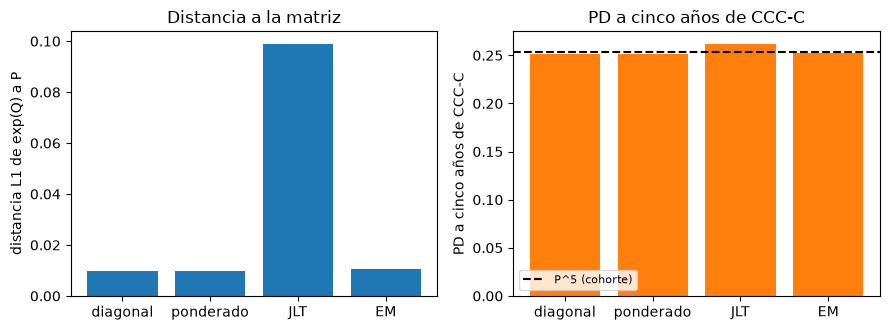

In [9]:
# Dibujar la distancia L1 de cada generador candidato y la PD a cinco años de CCC-C que implica
names = ["diagonal", "weighted", "jlt", "em"]
labels = ["diagonal", "ponderado", "JLT", "EM"]
l1_values = [embedding.l1_distance(P, candidates[n]) for n in names]
pd5_values = [expm(5 * candidates[n])[6, -1] for n in names]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))
left.bar(labels, l1_values, color="tab:blue")
left.set_ylabel("distancia L1 de exp(Q) a P")
left.set_title("Distancia a la matriz")
right.bar(labels, pd5_values, color="tab:orange")
right.axhline(p5[6, -1], color="black", linestyle="--", label="P^5 (cohorte)")
right.set_ylabel("PD a cinco años de CCC-C")
right.set_title("PD a cinco años de CCC-C")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **No hay generador exacto.** La matriz agrupada de S&P tiene S = 0,121 (bajo 1, y toda entrada diagonal está sobre 1/2, así que un generador, si existiera, sería único) y su determinante 0,3364 queda entre 0 y el producto de la diagonal, 0,3471, así que las condiciones (a) y (b) del Teorema 3 no la excluyen. La condición (c) sí, en seis pares, y el Lema 1 encuentra cuatro violaciones de monotonía. Los diagnósticos igualan al bloque versionado.
- **La serie del logaritmo es exacta y no es un generador.** Suma 28 términos, queda a 1,7e-15 del `logm` de SciPy, devuelve la matriz a 1,4e-15 y tiene nueve entradas negativas fuera de la diagonal, la más negativa de CCC-C a BB (-0,0036).
- **Reparaciones y EM, por distancia.** La distancia L1 de exp(Q) a la matriz es 0,00998 para la reparación diagonal, 0,00980 para la ponderada, 0,01063 para el generador EM y 0,0989 para JLT, diez veces más lejos porque supone a lo más una transición al año. Las cuatro igualan los valores versionados.
- **La elección se nota a cinco años.** A un año los generadores dan a B y CCC-C la PD de la matriz con menos de 0,05 puntos de diferencia para diagonal, ponderado y EM, y 1,5% frente a 1,17% para B con JLT. A cinco años CCC-C es 25,30% por la matriz a la quinta, 25,15% diagonal, 25,09% ponderado, 25,27% EM y 26,18% JLT; AAA pasa de exactamente 0 a un año (la matriz) a 0,007% con todo generador, y a 0,102% (P^5), 0,127%, 0,126%, 0,123% y 0,138% a cinco años.
- **Contra lo impreso.** Ocho de las nueve distancias L1 que imprimen Israel et al. se reproducen hasta los dígitos impresos. La novena, JLT sobre S&P 1981 a 1991, imprime 0,1169 donde la ecuación (3) sobre la matriz impresa da 0,1165; partiendo del generador impreso con cuatro dígitos la misma distancia es 0,1169, así que lo impreso sigue al generador, no a la matriz.

Lo que este cuaderno no muestra: si el modelo de Markov se ajusta a los datos (cuaderno 04), ni un generador con condicionamiento macroeconómico (cuaderno 08).

## Resumen

- Una matriz anual tiene un generador exacto solo si la serie del logaritmo converge, ninguna condición del Teorema 3 la excluye y el resultado tiene entradas fuera de la diagonal no negativas; una matriz empírica rara vez lo cumple.
- Las reparaciones diagonal y ponderada y el generador EM quedan cerca de la matriz; JLT queda diez veces más lejos aquí.
- El generador es parte de la PD a un horizonte más largo: la PD a cinco años de CCC-C se mueve cerca de un punto entre los candidatos, y un grado con PD anual cero recibe una positiva.
- Una recomputación que no coincide con lo impreso se informa con su explicación, nunca se ajusta.

**Qué probar después.** Calcula la serie del logaritmo de la matriz de la cohorte 2000 del cuaderno 01 y mira cuántas entradas negativas da un solo año; luego lee el cuaderno 04.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Israel, R. B., Rosenthal, J. S. y Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2), 245-265, Teoremas 1 a 3, Lema 1 y ecuaciones (2), (2') y (3). https://doi.org/10.1111/1467-9965.00114
- Jarrow, R. A., Lando, D. y Turnbull, S. M. (1997), A Markov model for the term structure of credit risk spreads, Review of Financial Studies 10(2), según lo cita el motor para la ecuación (3) y el Lema 1.
- Bladt, M. y Sorensen, M. (2005), Journal of the Royal Statistical Society B 67(3), y Smith, A. y dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, para el generador EM.